The transition model assigns probabilities to candidate pass destinations, conditional on attempting a pass. This differs from the probability that a pass succeeds. The operational final specification uses a shared XGBoost utility followed by categorical softmax; a cross-nested alternative was also evaluated.

The [benchmark](../../benchmark.qmd#pass-selection-benchmark) documents the five-configuration screening, exact 6+2+2 match splits, fold-specific physical features and both final runs. Pooled McFadden values are 33.878% for flat and 34.091% for CNL after validation-only temperature calibration. We retain flat for deployment. The verified full-data flat refit is installed (1,420 trees, T=1.021997). Its saved xT, vocabulary and full-data physics identities are bundled with the ensemble. The CNL refit remains in research history.

## What the final model sees

The numerical features describe pass geometry, carrier speed, raw target pitch control, own/opponent xT and pressure-line index at the target and carrier, one-second ball-drive loss, minute, known score difference, and players bypassed. Raw start type and previous action are one-hot encoded using a saved fit-only vocabulary. No realized receiver or future event enters the predictors. Pressure-line index uses the nearest of three ordered line centres.

## Training and references

Utilities start at zero. Training minimizes full-choice categorical NLL; candidate cells are not separate Bernoulli trials. The CNL alternative forms teammate memberships from normalized individual raw pitch control, shares one dissimilarity μ, and jointly updates its reciprocal every 20 trees with 0.1 relaxation. Gradient/curvature and alternating updates follow the archived RUMBoost CPU references, with explicitly documented project adaptations (XGBoost, shared utility/scale, fixed physics memberships and conditional scalar scan).

Sources: [Fernández et al. 2021](https://link.springer.com/article/10.1007/s10994-021-05989-6), [RUMBoost](https://doi.org/10.1016/j.trc.2024.104897), [CNL extension](https://transp-or.epfl.ch/heart/2024/abstracts/hEART_2024_paper_8384.pdf), [released objective](https://github.com/big-ucl/rumboost/blob/v1.0.2/rumboost/rumboost.py), [later training code](https://github.com/big-ucl/rumboost/blob/main/rumboost/rumboost.py), [XGBoost](https://arxiv.org/abs/1603.02754), [temperature scaling](https://proceedings.mlr.press/v70/guo17a.html). The benchmark links the archived source hashes and the physical-model references.

## Normalization example

The following deterministic scores illustrate the categorical denominator; they are not a benchmark fit.

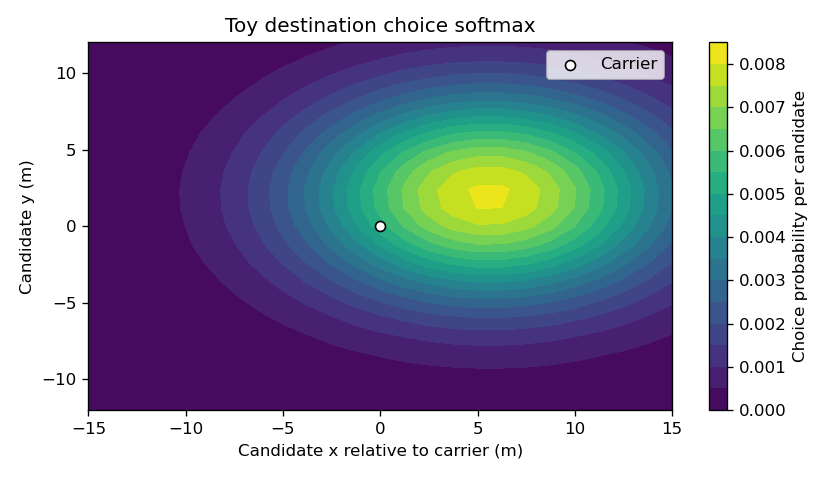

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Deterministic toy candidate scores; this demonstrates the wrapper's softmax normalization.
x,y=np.meshgrid(np.linspace(-15,15,25),np.linspace(-12,12,21)); score=-(x-4)**2/90-(y-2)**2/45+0.035*x
flat=score.ravel(); e=np.exp(flat-flat.max()); p=e/e.sum(); field=p.reshape(score.shape)
fig,ax=plt.subplots(figsize=(7,4)); im=ax.contourf(x,y,field,levels=18,cmap="viridis"); fig.colorbar(im,ax=ax,label="Choice probability per candidate"); ax.scatter([0],[0],c="white",edgecolor="black",label="Carrier"); ax.set(xlabel="Candidate x relative to carrier (m)",ylabel="Candidate y (m)",title="Toy destination choice softmax"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_03_transition.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.

The pitch view below uses the package plotting function and the computed values for frame 5, inside an action interval rather than at its start. It shows probability mass on the original candidate destinations, conditional on passing. Candidate fields use a coarse demonstration grid; the synthetic fixture and grid are not a benchmark.


model: skillcorner_outfield_pass_selection_flat_v2
choice probabilities: [1.23219482e-06 5.14265838e-06 3.32428675e-05 8.09319469e-05
 4.97094095e-04 1.82995720e-03 7.26002471e-05 4.13860019e-04
 3.82966597e-04 8.95185171e-04 8.87825133e-04 2.85824901e-04
 3.11832438e-05 8.14480960e-07 2.82755226e-05 9.42518688e-05
 7.33133305e-04 7.56877239e-04 1.63332859e-01 2.99129514e-04
 9.87432271e-04 1.23316548e-03 1.59362017e-03 4.27406431e-04
 2.35976634e-04 8.04890217e-05 9.56827994e-06 7.03283872e-05
 3.64944600e-04 1.93074828e-04 1.83185920e-03 3.75691885e-02
 2.51215086e-03 2.54618947e-03 4.95648131e-02 3.39419588e-03
 1.61634455e-03 6.81375138e-04 2.95841263e-04 7.50868554e-06
 2.10791604e-04 6.58391219e-04 5.73352799e-04 3.25617762e-03
 1.61183033e-03 1.56329176e-03 5.20430838e-03 8.94997119e-02
 2.89061745e-03 7.65887647e-04 1.26855033e-03 1.51150088e-04
 7.42149620e-06 2.51871958e-04 4.87505583e-04 5.44962384e-04
 1.16567163e-03 5.33794669e-01 2.71137364e-03 2.22096833e-03
 4.80832692e

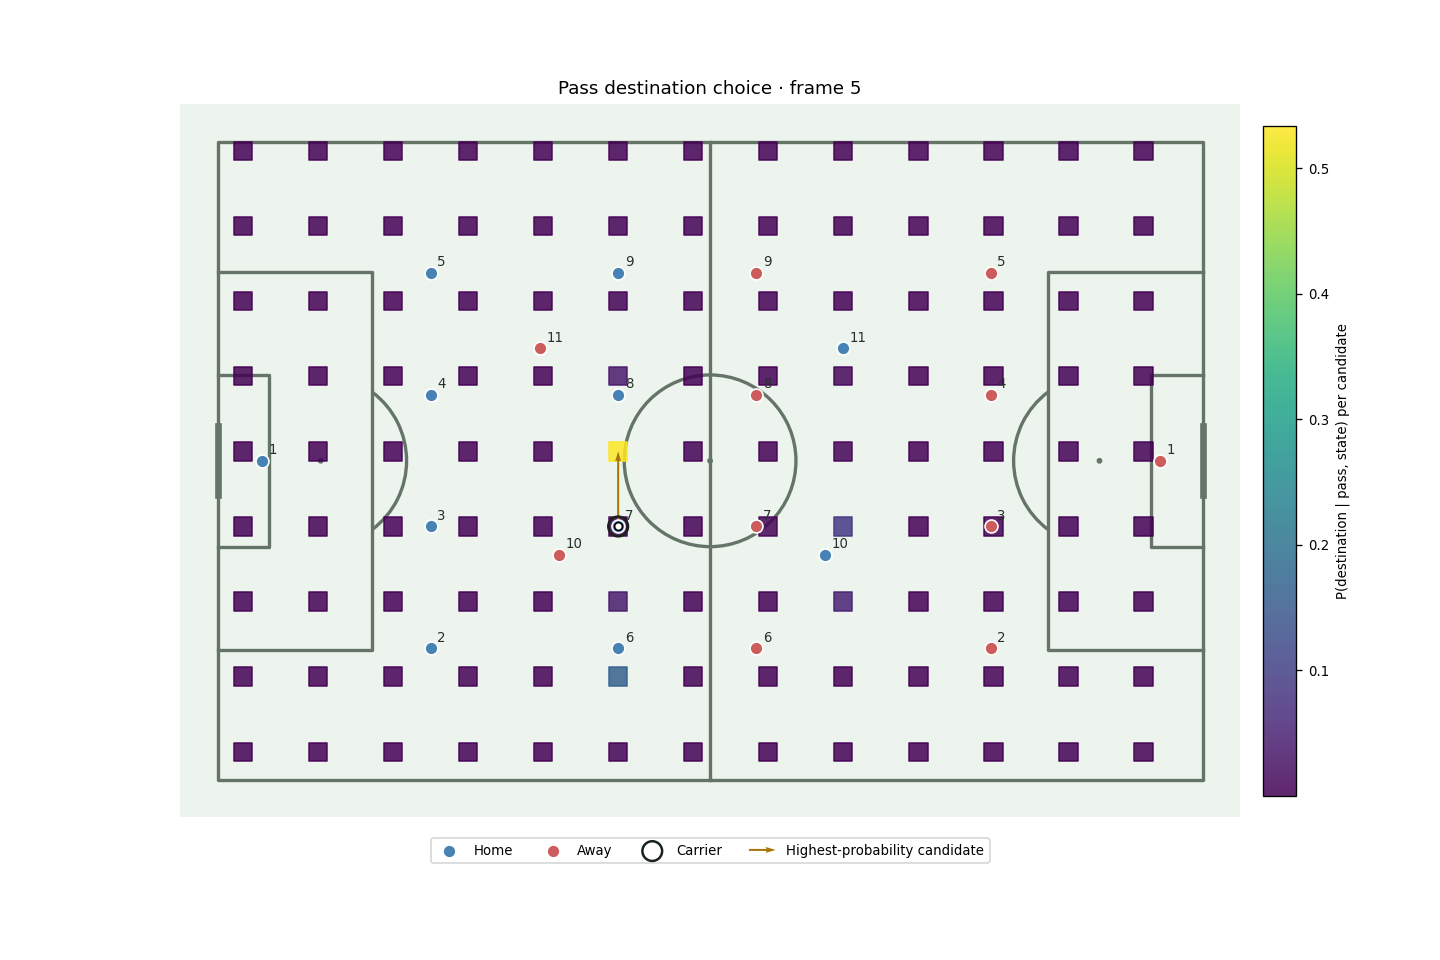

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
model.compute_ball_drive_loss(frame_id)
model.compute_transition_probabilities(frame_id, xT_grid, match_clock_min=0.5, score_difference_prefix=0)
result = model.get_ppcf_result(frame_id)
print("model:", result["transition_model_id"])
print("choice probabilities:", np.asarray(result["Transition probabilities"]))
print("probability sum:", float(np.sum(result["Transition probabilities"])))

from PRESS.visualization import plot_transition
fig, ax = plot_transition(model, frame_id)
out = Path("figures/vignette_03_transition_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


## Load a verified full-data export

The installed full-data model is available without fitting:

```python
from PRESS.model import PassSelectionModel
choice = PassSelectionModel.pretrained()
press = PRESS(tracking, pass_selection_model=choice)
press.compute_ppcf(frame_id)  # native full-pitch grid with the final choice model
press.compute_ball_drive_loss(frame_id, t_press=1.0)
probability = press.compute_transition_probabilities(
    frame_id, xT_grid,
    start_type_raw="pass_reception", previous_action_raw="ball_drive",
    match_clock_min=32.5, score_difference_prefix=0,
)
```

Use the actual raw context labels at the frame. The model reads its own fitted xT and vocabulary; the positional `xT_grid` remains for legacy API compatibility. The runnable demo above uses this installed flat ensemble on a deliberately coarse grid. The default full native grid matches the benchmark; changing its cells changes the categorical denominator. `from_json(path)` can load another verified export explicitly. The secondary CNL refit is retained in research history.